# Parametric insurance in ten minutes

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RiskThinking/crc-docs/blob/main/notebooks/parametric_insurance_primer.ipynb)

A normal insurance policy pays **what you lost**, after someone has come to look.
A **parametric** policy pays **what a measured number says**: if the rain on one
day passes an agreed level, an agreed amount is paid. No adjuster, no claim form,
no argument about the size of the loss.

This is not a curiosity. Two public schemes show the idea at national scale:

- **CCRIF SPC** describes itself as the
  [world's first multi-country, multi-peril risk pool based on parametric insurance](https://www.ccrif.org/about-us?language_content_entity=en).
  Its 40 members are mostly Caribbean and Central American governments and
  utilities, and by its own count it made 83 payouts totalling about US$500 million
  between June 2007 and October 2026. One of them went to
  [Panama: US$26.7 million after the excess rainfall of 31 October to 4 November 2024](https://www.ccrif.org/news/government-panama-receives-us267-million-following-excess-rainfall-event?language_content_entity=en).
- **African Risk Capacity (ARC)** insures African governments against drought. A
  member [receives a payout when rainfall deviates enough](https://www.arc.int/how-arc-works)
  that the response costs estimated by its model, Africa RiskView, cross a
  threshold agreed in advance, and ARC says the money arrives two to four weeks
  after the rainy season ends. Its
  [risk-pool record](https://www.arc.int/risk-pools) lists US$206.1 million of
  payouts, 13 risk pools and 20 member states covered.

Speed is the selling point. The catch is that the payout follows the number, not
your loss. This primer shows what that means, one chart per idea, using the
parametric module of the open toolkit
[crc-sdk](https://github.com/RiskThinking/crc-sdk).

**The one thing to take away: a cover is a function you can design, and test
honestly, including when it fails to pay.**

You should know what a hazard curve is
([five-minute primer](climate_risk_curves_primer.ipynb) if not), but you need no
insurance background. On Colab choose **Runtime → Run all**; no account needed.
The sliders and buttons work once it runs; on GitHub you see saved images of them.

## Setup

In [1]:
#@title Install packages (Colab)
import importlib.util
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google") is not None and importlib.util.find_spec("google.colab") is not None

# crc_sdk.parametric is not in a crc-sdk release yet: install it from its development branch.
CRC_SDK = "crc-sdk[geometry,zarr,netcdf,parametric] @ git+https://github.com/marc272/crc-sdk@parametric"


def has_parametric():
    spec = importlib.util.find_spec("crc_sdk")
    return (spec is not None and spec.origin is not None
            and (Path(spec.origin).parent / "parametric" / "__init__.py").is_file()
            and importlib.util.find_spec("highspy") is not None)


def pip_install(*arguments):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "--disable-pip-version-check", *arguments])


if IN_COLAB or not has_parametric():
    if importlib.util.find_spec("pip") is None:
        subprocess.check_call([sys.executable, "-m", "ensurepip", "--upgrade"], stdout=subprocess.DEVNULL)
    pip_install(CRC_SDK, "plotly>=6,<7", "pandas>=2.2")
    if not has_parametric():  # a crc-sdk release of the same version number may already be installed
        pip_install("--force-reinstall", "--no-deps", CRC_SDK)
    importlib.invalidate_caches()

# Small, quick runs for continuous integration; the same code runs either way.
CI = os.environ.get("CRC_DOCS_CI") == "1"

In [2]:
import warnings

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
import pyarrow as pa
import pyarrow.compute as pc
from IPython.display import display
from plotly.subplots import make_subplots

from crc_sdk.impacts import ImpactCalibration, ImpactExpression
from crc_sdk.parametric import (
    MSE, AnnualSeries, Budget, CostOfCapitalLoad, Cover, ExpectedUncovered, Free, FreshDraws,
    IndexDefinition, Limit, LinearPayout, LossModel, MetricOptions, ParametricPlan, PiecewiseLinearPayout,
    PurePremium, WeightedCVaR, compare, design, evaluate, sample_curve, setup_text,
)
from crc_sdk.workflows import BlockExtremaPolicy, HazardDataset, distribution_from_hazard_row
from crc_sdk.workflows.distributions import ReturnPeriodExtrapolationWarning

# Interactive charts when you run it; saved images so GitHub can show them too.
STATIC_PREVIEW = os.environ.get("CRC_NOTEBOOK_STATIC_PREVIEW") == "1"
pio.renderers.default = (
    "colab" if IN_COLAB else "plotly_mimetype+png" if STATIC_PREVIEW else "plotly_mimetype"
)
pio.templates.default = "plotly_white"
pio.defaults.default_width = 1000

DATA = Path("data") / "parametric_primer"
DATA.mkdir(parents=True, exist_ok=True)

# Orange is always the loss and blue the payout; the design goals have a colour each.
INK, BLUE, ORANGE, GREEN, MUTED, LIGHT = "#52514e", "#2a78d6", "#eb6834", "#1baf7a", "#8a8880", "#f0efec"
FONT = dict(family="Inter, Helvetica, Arial, sans-serif", size=14)


def layout(fig, title, setup, height=500, bottom=70, top=120, **kwargs):
    """Style a chart and state its setup under the title, so the numbers never lose it."""
    fig.update_layout(title=dict(text=title, x=0.01, y=0.97, yanchor="top",
                                 subtitle=dict(text=setup, font=dict(size=11, color=MUTED))),
                      font=FONT, height=height, margin=dict(l=75, r=30, t=top, b=bottom), hoverlabel=dict(font_size=13), **kwargs)
    return fig


def cad(value):
    return f"CAD {value:,.0f}"

## The example: a brewery with a wet basement

Imagine **Wet Basement Brewing**, a craft brewery in Toronto with its tanks and
cold room below street level. It is made up: the name, its value of CAD 5 million
and the way it floods are illustrations, not a real business or a real contract.

Three ingredients go in:

1. **The rain.** CRC Open's `rx1day`, the rain on the wettest day of the year, for
   the hexagon around the site (about 250 km²). The public release covers one
   high-emissions future, SSP5-8.5, and we read its 2030 horizon. CRC Open has no
   historical baseline, so everything simulated below describes that future, not
   the past.
2. **The damage.** A hypothetical curve, written down below. Nothing happens up to
   40 mm in a day; beyond that the drains give up and the damage climbs.
3. **The gap between the rain and the loss.** We come back to it in section 3.

In [3]:
RELEASE = "ssp585-global-2026-10-20-v1"
HORIZON, PATHWAY = 2030, "ssp585"
ASSET = {"asset_id": "Wet Basement Brewing", "longitude": -79.38, "latitude": 43.65, "value_cad": 5_000_000.0}
BOUNDS = (-79.40, 43.63, -79.36, 43.67)  # (west, south, east, north), enough to find the site's hexagon

# Downloads and checks the CRC Open files once, then reads the cached copy.
dataset = (
    HazardDataset.crc_open(release=RELEASE)
    .hazards(["rx1day"])
    .horizons([HORIZON])
    .for_area(BOUNDS)
    .cache(DATA / "crc-open", mode="reuse")
    .ensure_materialized()
)
metadata = dataset.metadata()

DAMAGE = ImpactExpression.tabulated(
    [(40.0, 0.0), (50.0, 0.02), (60.0, 0.06), (75.0, 0.15), (100.0, 0.30)],
    calibration=ImpactCalibration(exposure_variable="rx1day", exposure_unit="mm/day",
                                  impact_metric="damage_ratio", impact_unit="1"),
    clamp={"minimum": 0.0, "maximum": 1.0},
)
assets = pa.Table.from_pylist([ASSET])
request = (
    dataset.for_assets(assets)
    .select(hazard_names=["rx1day"], horizons=[HORIZON], pathways=[PATHWAY])
    .impact(DAMAGE, name="basement_damage", value_unit="1", value_semantics="hypothetical damage ratio")
)
curve_row = request.asset_curves().to_pylist()[0]
curve = distribution_from_hazard_row(curve_row)

frequent, rare = metadata.source_probability_support
print(f"CRC Open rx1day ({metadata.value_unit}), release {RELEASE}, pathway {PATHWAY}, horizon {HORIZON}, "
      f"hexagon {curve_row['cell_index']:x}.")
print(f"Declared meaning: {metadata.probability_semantics}, so one draw from the curve is one year. "
      f"Fitted between return periods {1 / (1 - frequent):.3f} and {1 / (1 - rare):,.0f} years; "
      f"{metadata.ensemble.pooling} over an ensemble of climate models.")
print(f"Licence: {metadata.source.licence}. Attribution: {metadata.source.attribution}.")

CRC Open rx1day (mm/day), release ssp585-global-2026-10-20-v1, pathway ssp585, horizon 2030, hexagon 852b9bc7fffffff.
Declared meaning: annual_value_distribution, so one draw from the curve is one year. Fitted between return periods 1.001 and 1,000 years; pooled over an ensemble of climate models.
Licence: CC-BY-NC-4.0. Attribution: Riskthinking.AI bias-corrected climate distributions.


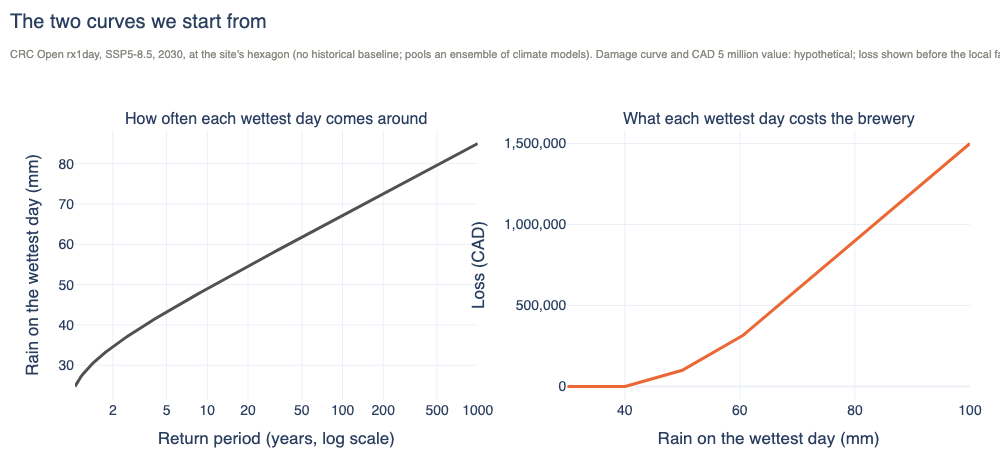

In [4]:
periods = np.geomspace(1.05, 1_000, 200)
rain = np.asarray(curve.quantiles(1 - 1 / periods), dtype=float)
rain_grid = np.linspace(30.0, 100.0, 141)
loss_grid = ASSET["value_cad"] * np.asarray(DAMAGE.evaluate(rain_grid), dtype=float)

fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.1,
                    subplot_titles=("How often each wettest day comes around", "What each wettest day costs the brewery"))
fig.add_trace(go.Scatter(x=periods, y=rain, mode="lines", line=dict(color=INK, width=3), showlegend=False,
                         hovertemplate="1-in-%{x:.0f} years: %{y:.0f} mm<extra></extra>"), row=1, col=1)
fig.add_trace(go.Scatter(x=rain_grid, y=loss_grid, mode="lines", line=dict(color=ORANGE, width=3), showlegend=False,
                         hovertemplate="%{x:.0f} mm: loss CAD %{y:,.0f}<extra></extra>"), row=1, col=2)
fig.update_xaxes(type="log", tickvals=[1, 2, 5, 10, 20, 50, 100, 200, 500, 1000], title_text="Return period (years, log scale)", row=1, col=1)
fig.update_yaxes(title_text="Rain on the wettest day (mm)", row=1, col=1)
fig.update_xaxes(title_text="Rain on the wettest day (mm)", row=1, col=2)
fig.update_yaxes(title_text="Loss (CAD)", tickformat=",.0f", row=1, col=2)
layout(fig, "The two curves we start from",
       f"CRC Open rx1day, SSP5-8.5, {HORIZON}, at the site's hexagon (no historical baseline; pools an ensemble of climate models). "
       f"Damage curve and CAD 5 million value: hypothetical; loss shown before the local factor of section 3.", height=470, top=130)
fig.show()

Now the simulated years. `sample_curve` rolls the curve once per year, and for
each roll gets the rain (the **index** the cover will pay on) and the loss. We
simulate two separate sets: **design years** for choosing a cover's terms, and
**fresh years** that are only ever used to test it.

Every number from here on is computed on the fresh years, unless it says otherwise.

In [5]:
class LocalRainFactor:
    """Basis risk: rain at the brewery = rain on the hexagon x a random local factor.

    An assumption of this example, not an estimate. It follows the module's `BasisRisk` protocol:
    `apply` returns the index and the impact for each year; here the index stays the hexagon's rain,
    and the impact is the damage curve at the brewery's own rain.
    """

    name = "local_rain_factor"

    def __init__(self, sigma, damage):
        self.sigma, self.damage = sigma, damage

    def to_document(self):
        return {"kind": self.name, "sigma": self.sigma, "damage": self.damage.definition_hash}

    def apply(self, index, hazard, impact, rng):
        factor = np.exp(rng.normal(-self.sigma**2 / 2, self.sigma, size=hazard.shape))
        return index, np.asarray(self.damage.evaluate((hazard * factor).ravel()), dtype=float).reshape(hazard.shape)


SIGMA = 0.25
loss_model = LossModel(DAMAGE, value=ASSET["value_cad"], value_unit="CAD")
basis_risk = LocalRainFactor(SIGMA, DAMAGE)
N_YEARS = 2_000 if CI else 20_000


def simulate(seed, n_years=N_YEARS, basis_risk=basis_risk):
    # One generator per sample, spawned the way a ParametricPlan spawns it for its first asset.
    rng = np.random.default_rng(np.random.SeedSequence(seed).spawn(1)[0])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ReturnPeriodExtrapolationWarning)  # counted, and stated by setup_text below
        return sample_curve(curve_row, metadata=metadata, n_draws=n_years, rng=rng, loss_model=loss_model,
                            basis_risk=basis_risk, asset_id=ASSET["asset_id"])


design_years = simulate(seed=42)
fresh_years = simulate(seed=7)
rain_years = fresh_years.index[:, 0]   # the index: rain on the hexagon, one value per simulated year
loss_years = fresh_years.loss[:, 0]    # the loss, in CAD
print(f"{N_YEARS:,} design years and {N_YEARS:,} fresh years. Fresh years: "
      f"mean loss {cad(loss_years.mean())} a year, a loss in {(loss_years > 0).mean():.0%} of years.")

BASE_SETUP = (f"Setup: one imaginary asset · annual basis, one draw = one year · basis risk: local-rain factor σ = {SIGMA} · "
              f"CRC Open rx1day, SSP5-8.5, {HORIZON} (no historical baseline) ·<br>hypothetical damage and value · ")
FRESH_SETUP = BASE_SETUP + f"out of sample: {N_YEARS:,} fresh simulated years"

20,000 design years and 20,000 fresh years. Fresh years: mean loss CAD 62,408 a year, a loss in 33% of years.


## 1. A cover is a function

A parametric cover is a **function**: rain in, money out. Here is a simple one
for the brewery. Pay nothing below 45 mm in a day (the **attachment**), pay the
full CAD 500,000 from 75 mm (the **exhaustion**), and rise in a straight line
between the two. That is one line of code:

In [6]:
index = IndexDefinition("rx1day", "mm/day", aggregation="annual_maximum")
first_cover = Cover(index, LinearPayout(45.0, 75.0, 500_000.0), payout_unit="CAD", label="First cover")

first_cover.payout_values([30.0, 45.0, 60.0, 90.0])   # rain in, CAD out

array([     0.,      0., 250000., 500000.])

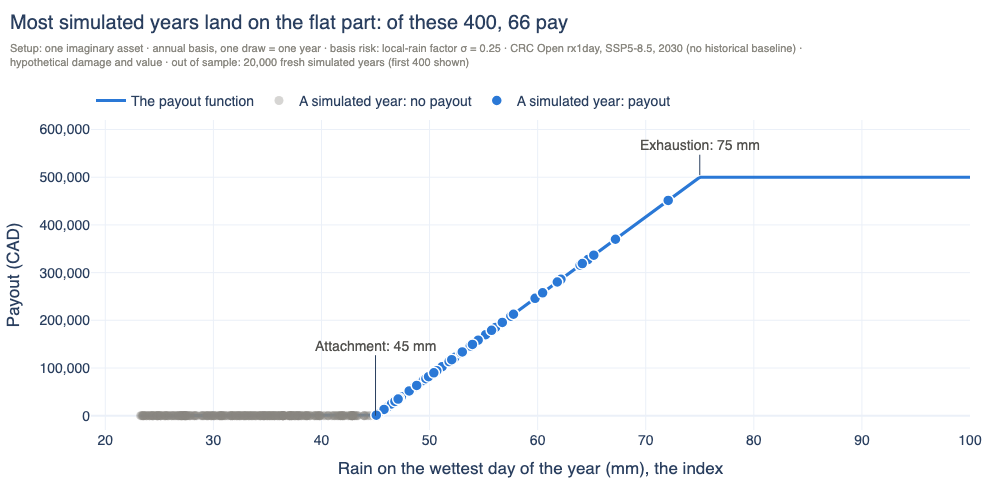

In [7]:
paid = first_cover.payout_values(rain_years)
shown = np.arange(min(400, N_YEARS))
grid = np.linspace(rain_years[shown].min(), max(100.0, rain_years[shown].max()), 300)

fig = go.Figure()
fig.add_trace(go.Scatter(x=grid, y=first_cover.payout_values(grid), mode="lines", line=dict(color=BLUE, width=3),
                         name="The payout function", hovertemplate="%{x:.0f} mm: pays CAD %{y:,.0f}<extra></extra>"))
pays = paid[shown] > 0
fig.add_trace(go.Scatter(x=rain_years[shown][~pays], y=paid[shown][~pays], mode="markers", name="A simulated year: no payout",
                         marker=dict(size=9, color=MUTED, opacity=0.35, line=dict(width=0)),
                         hovertemplate="Rain %{x:.0f} mm: no payout<extra></extra>"))
fig.add_trace(go.Scatter(x=rain_years[shown][pays], y=paid[shown][pays], mode="markers", name="A simulated year: payout",
                         marker=dict(size=11, color=BLUE, line=dict(width=1.5, color="white")),
                         hovertemplate="Rain %{x:.0f} mm: pays CAD %{y:,.0f}<extra></extra>"))
fig.add_annotation(x=45, y=0, text="Attachment: 45 mm", showarrow=True, arrowhead=0, ax=0, ay=-70, font=dict(color=INK))
fig.add_annotation(x=75, y=500_000, text="Exhaustion: 75 mm", showarrow=True, arrowhead=0, ax=0, ay=-30, font=dict(color=INK), yshift=2)
layout(fig, f"Most simulated years land on the flat part: of these {len(shown)}, {int(pays.sum())} pay",
       FRESH_SETUP + f" (first {len(shown)} shown)",
       xaxis_title="Rain on the wettest day of the year (mm), the index", yaxis=dict(title="Payout (CAD)", tickformat=",.0f", range=[-30_000, 620_000]),
       legend=dict(orientation="h", yanchor="bottom", y=1.01, x=0))
fig.show()

> 💡 **Key idea: the contract is a function.** A cover is an **index**, a
> **payout function** and a currency, and that is all of it.
> Here `payout = 500,000 × clip((rain − 45) / (75 − 45), 0, 1)`. The module also
> ships a step payout, a piecewise-linear payout and an all-or-nothing payout,
> and you can write your own. Because the terms are just data, a cover can be
> saved, hashed and compared exactly (`first_cover.to_json()`,
> `first_cover.definition_hash`).

## 2. How often does it pay?

The brewery pays its premium every year. The payout comes only sometimes. Here
are 100 simulated years, with the loss and the payout of each. Drag the slider to
roll another 100.

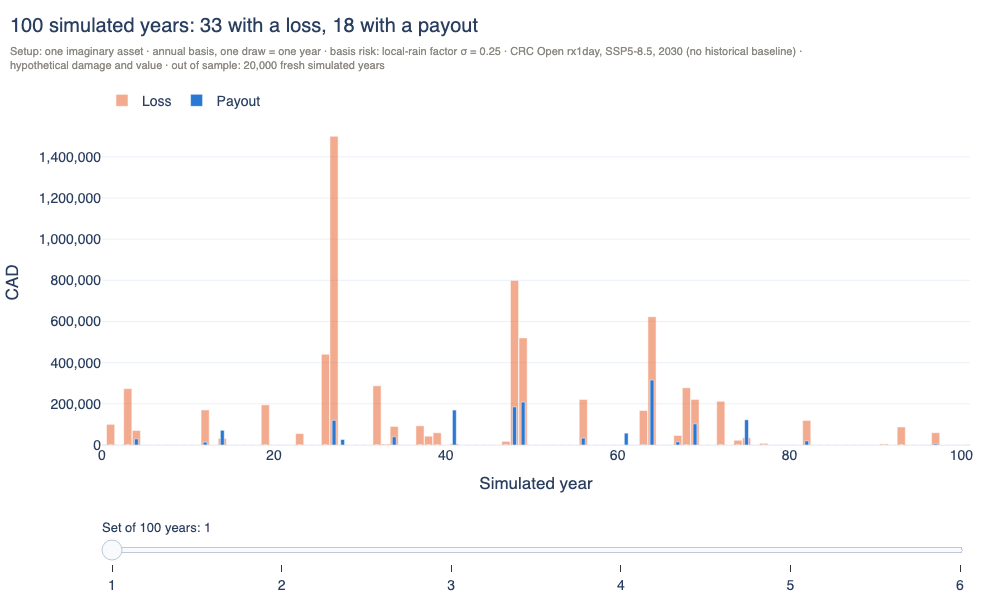

Across all 20,000 fresh years: the cover pays in 16.6% of years (about 1 in 6), and the brewery has a loss in 32.5% of years.


In [8]:
CENTURIES = 6 if not CI else 3
years_axis = np.arange(1, 101)
fig = go.Figure()
for century in range(CENTURIES):
    start, stop = century * 100, (century + 1) * 100
    fig.add_trace(go.Bar(x=years_axis, y=loss_years[start:stop], name="Loss", marker_color=ORANGE, opacity=0.55,
                         visible=century == 0, width=0.95, legendgroup="loss", showlegend=True,
                         hovertemplate="Year %{x}: loss CAD %{y:,.0f}<extra></extra>"))
    fig.add_trace(go.Bar(x=years_axis, y=paid[start:stop], name="Payout", marker_color=BLUE,
                         visible=century == 0, width=0.45, legendgroup="payout", showlegend=True,
                         hovertemplate="Year %{x}: payout CAD %{y:,.0f}<extra></extra>"))


def visible_century(century):
    return [index // 2 == century for index in range(2 * CENTURIES)]


def century_title(century):
    start, stop = century * 100, (century + 1) * 100
    return (f"100 simulated years: {(loss_years[start:stop] > 0).sum()} with a loss, "
            f"{(paid[start:stop] > 0).sum()} with a payout")


layout(fig, century_title(0), FRESH_SETUP, barmode="overlay", bargap=0.2,
       xaxis=dict(title="Simulated year", range=[0, 101]), yaxis=dict(title="CAD", tickformat=",.0f", rangemode="tozero"),
       legend=dict(orientation="h", yanchor="bottom", y=1.01, x=0), height=600, bottom=130,
       sliders=[dict(active=0, currentvalue=dict(prefix="Set of 100 years: ", font=dict(size=13)), pad=dict(t=70),
                     steps=[dict(method="update", label=str(century + 1),
                                 args=[{"visible": visible_century(century)}, {"title.text": century_title(century)}])
                            for century in range(CENTURIES)])])
fig.show()

print(f"Across all {N_YEARS:,} fresh years: the cover pays in {(paid > 0).mean():.1%} of years (about 1 in {1 / (paid > 0).mean():.0f}), "
      f"and the brewery has a loss in {(loss_years > 0).mean():.1%} of years.")

> 💡 **Key idea: most years, nothing happens.** A cover is a claim on rare years.
> That is why a return-period curve, which you already know how to read, is the
> right tool for pricing and testing it. It also means the honest test needs a lot
> of years: 30 years of history would contain only a handful of payouts.

## 3. Basis risk: when the rain and the loss disagree

The payout follows the rain on the hexagon. The loss follows the water in the
basement. A hexagon of 250 km² can be soaked by a storm that misses the brewery,
or stay dry on average while a storm sits right on top of it. To show that, we
assume a yearly **local factor** between the rain on the hexagon and the rain at
the brewery (`LocalRainFactor` above: lognormal with mean 1 and σ = 0.25). It is an
assumption of this illustration, not an estimate, and a real project would measure
it.

The gap is called **basis risk**, and it can fail in two opposite ways: a loss
with no payout, and a payout with no loss.

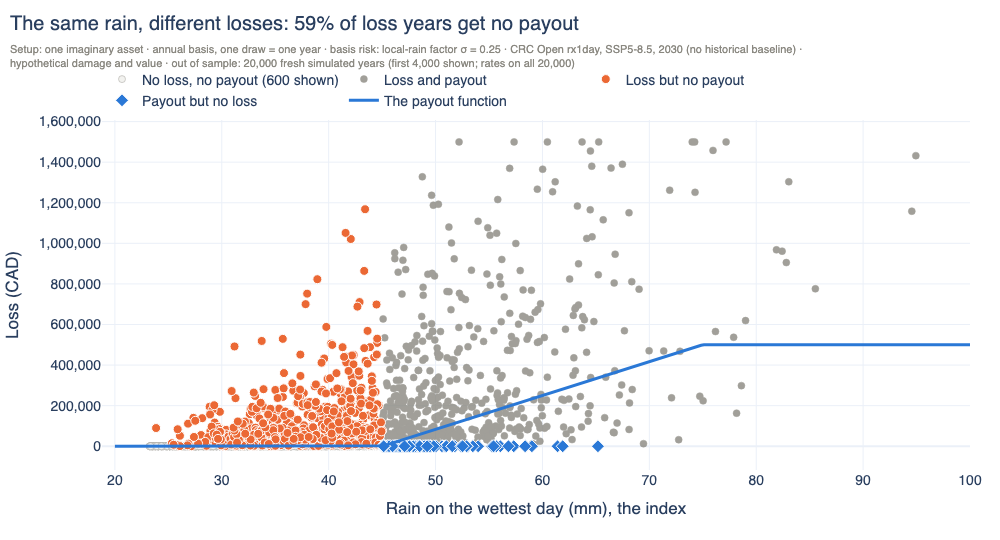

On the fresh years: 58.6% of the years with a loss get no payout, and 4.7% of the years without a loss get one. Payouts and losses have a correlation of 0.61.


In [9]:
OPTIONS = MetricOptions(betas=(0.9,), return_periods=(10, 100), loss_thresholds=(0.0,))
first_row = evaluate(first_cover, fresh_years, split="out_of_sample", design_sample=design_years, options=OPTIONS).to_pylist()[0]

n_shown = min(4_000, N_YEARS)
x, y, payout = rain_years[:n_shown], loss_years[:n_shown], paid[:n_shown]
missed = (y > 0) & (payout == 0)          # a loss, but no payout
false_alarm = (y == 0) & (payout > 0)     # a payout, but no loss
quiet = (y == 0) & (payout == 0)
other = ~(missed | false_alarm | quiet)

fig = go.Figure()
keep_quiet = np.flatnonzero(quiet)[:600]   # the many quiet years would hide the rest
for mask, name, color, size in [(keep_quiet, "No loss, no payout (600 shown)", LIGHT, 7), (other, "Loss and payout", MUTED, 7)]:
    fig.add_trace(go.Scatter(x=x[mask], y=y[mask], mode="markers", name=name, opacity=0.8,
                             marker=dict(size=size, color=color, line=dict(width=0.5, color=MUTED)), hoverinfo="skip"))
fig.add_trace(go.Scatter(x=x[missed], y=y[missed], mode="markers", name="Loss but no payout",
                         marker=dict(size=9, color=ORANGE, line=dict(width=1, color="white")),
                         hovertemplate="Rain on the hexagon %{x:.0f} mm<br>Loss CAD %{y:,.0f}, payout CAD 0<extra></extra>"))
fig.add_trace(go.Scatter(x=x[false_alarm], y=y[false_alarm], mode="markers", name="Payout but no loss",
                         marker=dict(size=10, color=BLUE, symbol="diamond", line=dict(width=1, color="white")),
                         hovertemplate="Rain on the hexagon %{x:.0f} mm<br>No loss, payout CAD %{customdata:,.0f}<extra></extra>",
                         customdata=payout[false_alarm]))
grid = np.linspace(20.0, 100.0, 300)
fig.add_trace(go.Scatter(x=grid, y=first_cover.payout_values(grid), mode="lines", name="The payout function",
                         line=dict(color=BLUE, width=3), hoverinfo="skip"))
layout(fig, f"The same rain, different losses: {first_row['false_negative_rate_l0']:.0%} of loss years get no payout",
       FRESH_SETUP + f" (first {n_shown:,} shown; rates on all {N_YEARS:,})",
       xaxis_title="Rain on the wettest day (mm), the index", yaxis=dict(title="Loss (CAD)", tickformat=",.0f"),
       legend=dict(orientation="h", yanchor="bottom", y=1.01, x=0), height=540)
fig.show()

print(f"On the fresh years: {first_row['false_negative_rate_l0']:.1%} of the years with a loss get no payout, and "
      f"{first_row['false_positive_rate_l0']:.1%} of the years without a loss get one. "
      f"Payouts and losses have a correlation of {first_row['correlation']:.2f}.")

Orange marks the first way to fail: a loss the cover never paid for, because the
rain on the hexagon stayed below the attachment. Blue marks the second: the hexagon
reached the attachment, but the storm missed the brewery and left it no damage.

> 💡 **Key idea: basis risk is the price of a fast payout, and it is real.** In
> Malawi's 2015/16 drought, ARC's [policy did not trigger at first](https://www.arc.int/index.php/news/press-release-malawi-receive-usd-8m-insurance-payout-support-drought-affected-families)
> because the model showed few people affected. ARC's review found the model had
> worked as specified, but farmers had moved to a 90-day maize while the model
> assumed a 120–140-day one. ARC amended the policy and agreed a payout of about
> US$8.1 million. [ActionAid's review](https://actionaid.org/publications/2017/wrong-model-resilience)
> called the payment too little and too late. The model did what it was specified
> to do, and still missed the loss.

The module reports both failures for any cover (`false_negative_rate_l0`,
`false_positive_rate_l0`), so a cover can be judged on them rather than on its best
years.

## 4. What it costs

The fairest possible price is the **pure premium**: the expected payout, what the
cover pays out on average. A real insurer also holds capital for its worst year
and charges for that, so a real premium is higher. Both are one argument away:

In [10]:
PRICES = {"Pure premium: the expected payout": PurePremium(),
          "With a 6% cost of capital held against the 1-in-100 tail": CostOfCapitalLoad(0.06, 0.99)}
cost = pd.DataFrame({
    label: evaluate(first_cover, fresh_years, split="out_of_sample", design_sample=design_years,
                    pricing=pricing, options=OPTIONS).to_pylist()[0]
    for label, pricing in PRICES.items()
}).T[["premium", "expected_payout", "expected_loss"]].astype(float)
cost["premium / expected loss"] = cost["premium"] / cost["expected_loss"]
display(cost.style.format({"premium": "{:,.0f}", "expected_payout": "{:,.0f}", "expected_loss": "{:,.0f}",
                           "premium / expected loss": "{:.0%}"}))
print(f"CAD per year. One imaginary asset, annual basis, local-rain factor σ = {SIGMA}, out of sample on {N_YEARS:,} fresh "
      f"simulated years from CRC Open rx1day, SSP5-8.5, {HORIZON} (no historical baseline). "
      f"The cost-of-capital rate and level are illustrative, not a market quote.")

,premium,expected_payout,expected_loss,premium / expected loss
Pure premium: the expected payout,"21,661","21,661","62,408",35%
With a 6% cost of capital held against the 1-in-100 tail,"46,846","21,661","62,408",75%


CAD per year. One imaginary asset, annual basis, local-rain factor σ = 0.25, out of sample on 20,000 fresh simulated years from CRC Open rx1day, SSP5-8.5, 2030 (no historical baseline). The cost-of-capital rate and level are illustrative, not a market quote.


> 💡 **Key idea: the premium is a statement about the curve.** The pure premium is
> `E[payout]`: the payout function averaged over the rain curve, so it moves as the
> hazard moves. The loaded premium here is
> `P = (1 − rate) · E[payout] + rate · CVaR_q(payout)`, the module's
> `CostOfCapitalLoad(rate, q)`. A warmer or wetter curve changes the price without
> anyone touching the contract.

## 5. Designing a better one

*Better at what?* So far we picked the terms by hand. The module can choose them
for us if we say what "good" means. Keep the same rain and the same money, and ask
for three different things:

| Goal | In plain words | In the module |
|---|---|---|
| Track the loss | Pay as close to the loss as you can, every year; paying too much counts as much as paying too little | `MSE()` |
| Leave the least uncovered, on average | Reduce the part of the loss the payout doesn't cover, every year alike | `ExpectedUncovered()` |
| Protect the worst years | Put most of the weight on the worst tenth of the years for what's left uncovered | `WeightedCVaR(alpha=0.9, beta=0.9)` |

We give the cover a free shape (a payout that can change slope at 50, 55, 60, 70
and 85 mm, up to at most CAD 1 million) and let each goal spend the **same premium
budget**. Drag the slider to change the budget.

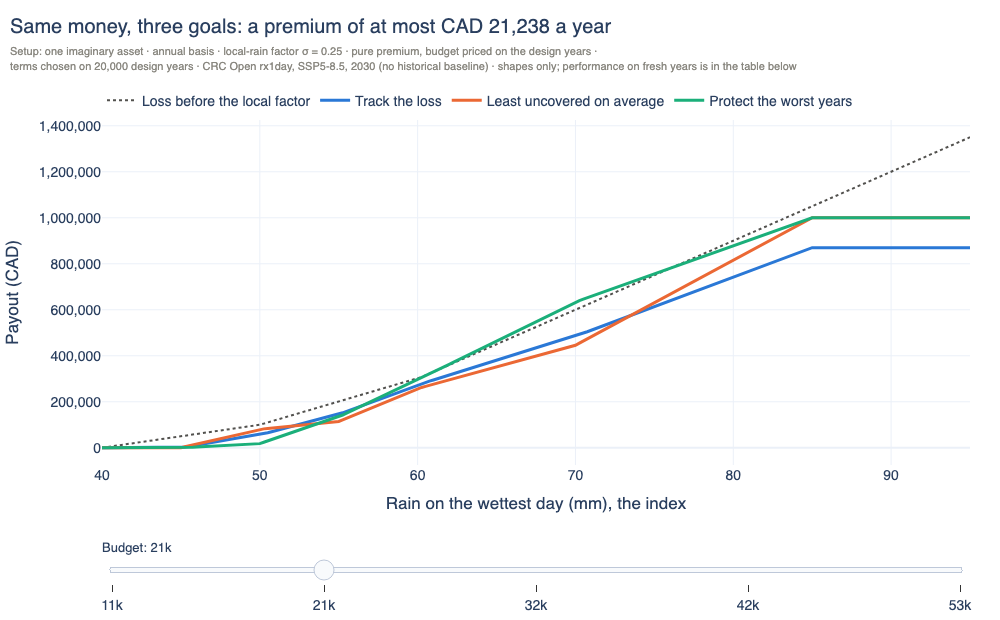

In [11]:
KNOTS = [45.0, 50.0, 55.0, 60.0, 70.0, 85.0]
GOALS = {
    "Track the loss": (MSE(), BLUE),
    "Least uncovered on average": (ExpectedUncovered(), ORANGE),
    "Protect the worst years": (WeightedCVaR(alpha=0.9, beta=0.9), GREEN),
}
# The first cover's premium on the design years, and multiples of it: "the same money" and more or less of it.
first_premium = evaluate(first_cover, design_years, split="in_sample", design_sample=design_years, options=OPTIONS).to_pylist()[0]["premium"]
BUDGETS = tuple(multiple * first_premium for multiple in (0.5, 1.0, 1.5, 2.0, 2.5))
LIMIT = Limit(1_000_000.0)


def template(label):
    # The first level is fixed at zero, so the cover pays nothing at or below 45 mm. The other five are free.
    return Cover(index, PiecewiseLinearPayout(KNOTS, [0.0, Free(), Free(), Free(), Free(), Free()]),
                 payout_unit="CAD", label=label)


designs = {
    (budget, goal): design(template(goal), design_years, objective, budget=Budget(amount=budget), limit=LIMIT)
    for budget in BUDGETS
    for goal, (objective, _) in GOALS.items()
}

plot_rain = np.linspace(40.0, 95.0, 221)
fig = go.Figure()
fig.add_trace(go.Scatter(x=plot_rain, y=ASSET["value_cad"] * np.asarray(DAMAGE.evaluate(plot_rain), dtype=float),
                         mode="lines", name="Loss before the local factor", line=dict(color=INK, width=2, dash="dot"),
                         hovertemplate="%{x:.0f} mm: loss CAD %{y:,.0f}<extra></extra>"))
for budget in BUDGETS:
    for goal, (_, color) in GOALS.items():
        fig.add_trace(go.Scatter(x=plot_rain, y=designs[budget, goal].cover.payout_values(plot_rain), mode="lines", name=goal,
                                 line=dict(color=color, width=3), visible=budget == BUDGETS[1],
                                 hovertemplate=f"{goal}<br>%{{x:.0f}} mm: pays CAD %{{y:,.0f}}<extra></extra>"))


def visible_budget(budget):
    return [True] + [item == budget for item in BUDGETS for _ in GOALS]


def budget_title(budget):
    return f"Same money, three goals: a premium of at most {cad(budget)} a year"


layout(fig, budget_title(BUDGETS[1]),
       f"Setup: one imaginary asset · annual basis · local-rain factor σ = {SIGMA} · pure premium, budget priced on the design years ·<br>"
       f"terms chosen on {N_YEARS:,} design years · CRC Open rx1day, SSP5-8.5, {HORIZON} (no historical baseline) · shapes only; performance on fresh years is in the table below",
       xaxis_title="Rain on the wettest day (mm), the index", yaxis=dict(title="Payout (CAD)", tickformat=",.0f"),
       legend=dict(orientation="h", yanchor="bottom", y=1.01, x=0), height=620, bottom=130,
       sliders=[dict(active=1, currentvalue=dict(prefix="Budget: ", font=dict(size=13)), pad=dict(t=70),
                     steps=[dict(method="update", label=f"{budget / 1000:.0f}k",
                                 args=[{"visible": visible_budget(budget)}, {"title.text": budget_title(budget)}])
                            for budget in BUDGETS])])
fig.show()

In [12]:
BUDGET = BUDGETS[1]   # the same money as the first cover
chosen = [designs[BUDGET, goal] for goal in GOALS]
out_of_sample = compare([first_cover, *chosen], fresh_years, split="out_of_sample", design_sample=design_years, options=OPTIONS)
results = out_of_sample.to_pandas().set_index("cover_label")

COLUMNS = {"premium": "Premium (CAD)", "coverage_ratio": "Expected loss covered",
           "tail_coverage_b0_9": "Loss covered, worst 10% of years", "false_negative_rate_l0": "Loss years with no payout",
           "false_positive_rate_l0": "No-loss years with a payout", "rmse": "Typical miss, RMSE (CAD)"}
table = results[list(COLUMNS)].rename(columns=COLUMNS)
display(table.style.format({"Premium (CAD)": "{:,.0f}", "Typical miss, RMSE (CAD)": "{:,.0f}", "Expected loss covered": "{:.0%}",
                            "Loss covered, worst 10% of years": "{:.0%}", "Loss years with no payout": "{:.0%}",
                            "No-loss years with a payout": "{:.1%}"}))
print(setup_text(out_of_sample))

span = lambda column: f"{results[column].min():.1%} to {results[column].max():.1%}"
print(f"\nOn these fresh years the four covers keep within {span('coverage_ratio')} of the expected loss "
      f"and {span('tail_coverage_b0_9')} of the loss in the worst 10% of years.")

# What limits the cover here? The same terms and rain, without the local factor (a very small σ).
no_factor = LocalRainFactor(1e-6, DAMAGE)
without = evaluate(first_cover, simulate(seed=7, basis_risk=no_factor), split="out_of_sample",
                   design_sample=simulate(seed=42, basis_risk=no_factor), options=OPTIONS).to_pylist()[0]
print(f"The same first cover with no local factor would cover {without['coverage_ratio']:.0%} of an expected loss of "
      f"{cad(without['expected_loss'])}, against {first_row['coverage_ratio']:.0%} of {cad(first_row['expected_loss'])} with σ = {SIGMA}: "
      f"the factor makes the loss both harder to reach and larger (the damage curve is convex, so noise raises the average loss).")

,Premium (CAD),Expected loss covered,"Loss covered, worst 10% of years",Loss years with no payout,No-loss years with a payout,"Typical miss, RMSE (CAD)"
cover_label,,,,,,
First cover,"21,661",25%,25%,59%,4.7%,"149,036"
Track the loss,"21,238",25%,26%,59%,4.7%,"147,982"
Least uncovered on average,"21,238",25%,26%,59%,4.7%,"148,407"
Protect the worst years,"21,238",25%,27%,59%,4.7%,"149,017"


Level: asset (Wet Basement Brewing). Scenario: baseline. Basis: annual, one draw is one year.
Split: out of sample, fold 0, on fresh Monte Carlo draws: evaluated on 20000 simulated years (draws 0 to 19999); designed on 20000 simulated years (draws 0 to 19999); the leakage check passed: the two share no period of one source.
Sample: Monte Carlo draws from a hazard curve with annual_value_distribution semantics, as the dataset declares. Basis risk: local_rain_factor (damage "sha256:c7eef8f12dda14fb2434b66b9db05108547944018bfc30fa67cdcff98600ecb7", sigma 0.25). Loss: impact expression tabulated (c7eef8f12dda) for hazard values in mm/day times a stated asset value, in CAD.
Source: the hazard curve rx1day from provider crc_open, dataset crc-open, horizon 2030 and pathway ssp585.
Sample notes: 30 of 20000 draws in the design sample and 22 of 20000 in the fresh draws are more frequent than the shortest fitted return period: the curve is extrapolated there. 17 of 20000 draws in the design samp

Read this as a description of this one setup, not as a ranking. The goals differ
in **which years they care about**, and that is the mechanism behind the shapes.
Tracking the loss punishes every miss, large misses most of all, whether the payout
is too small or too large. Leaving the least uncovered on average only counts what
the payout fails to cover. The worst-years goal counts mostly the worst tenth of the
years, so on this imaginary asset, under pure pricing at this budget, it pays less
around 50 mm and more around 70 mm than the other two.

At the same money the designs and the hand-drawn cover end up close to each other
here. In this setup the local factor, more than the payout shape, is what limits
how much of the loss any of these covers can reach. A design picks where to spend
the money; it can't make the index see storms it doesn't see.

None of the three goals is better in general. Change the site, the damage curve,
the price or the budget, and the shapes and the numbers change with them. The
designs keep the premium agreed on their design years, and the first cover's
premium is priced on the fresh years, so the small difference between those two is
sampling noise.

> 💡 **Key idea: a design goal is a choice about whose bad years you care about.**
> For a payout π and a loss L, with U = max(L − π, 0) the part left uncovered:
> `MSE` minimises E[(L − π)²], `ExpectedUncovered` minimises E[U], and
> `WeightedCVaR(α, β)` minimises α·CVaR_β(U) + (1 − α)·E[U].

## 6. Does it hold up on years it never saw?

Everything in the table came from **fresh years**, simulated separately from the
years the designs were chosen on. In the module, that is the difference between
`split="in_sample"` and `split="out_of_sample"`, and the module refuses to report
an out-of-sample number if the two sets overlap.

The honest question for the brewery: **in the years the cover is written for, how
bad does a bad year get, with and without it?** The exceedance curve below answers
that on the fresh years. It shows the yearly cost: the loss with no cover, and the
loss minus the payout plus the premium with one.

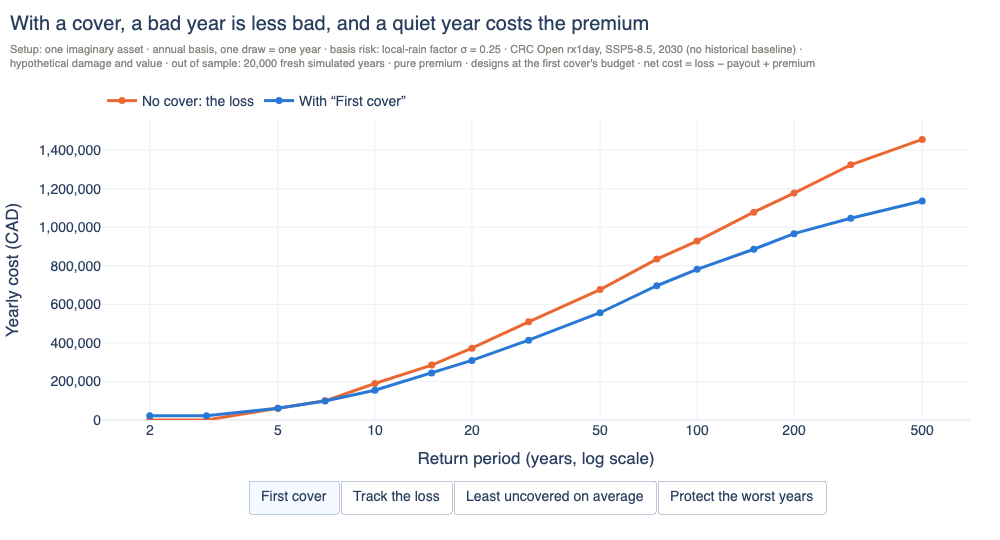

In [13]:
RETURN_PERIODS = (2, 3, 5, 7, 10, 15, 20, 30, 50, 75, 100, 150, 200, 300, 500)
curves = compare([first_cover, *chosen], fresh_years, split="out_of_sample", design_sample=design_years,
                 options=MetricOptions(betas=(0.9,), return_periods=RETURN_PERIODS, loss_thresholds=(0.0,))).to_pandas().set_index("cover_label")
loss_curve = curves.iloc[0][[f"loss_rp{period}" for period in RETURN_PERIODS]].astype(float).to_numpy()

COVERS_SHOWN = {"First cover": BLUE, **{goal: color for goal, (_, color) in GOALS.items()}}
fig = go.Figure()
fig.add_trace(go.Scatter(x=RETURN_PERIODS, y=loss_curve, mode="lines+markers", name="No cover: the loss",
                         line=dict(color=ORANGE, width=3), marker=dict(size=7),
                         hovertemplate="1-in-%{x} years: loss CAD %{y:,.0f}<extra></extra>"))
for number, (label, color) in enumerate(COVERS_SHOWN.items()):
    net = curves.loc[label, [f"net_loss_rp{period}" for period in RETURN_PERIODS]].astype(float).to_numpy()
    fig.add_trace(go.Scatter(x=RETURN_PERIODS, y=net, mode="lines+markers", name=f"With “{label}”", line=dict(color=color, width=3),
                             marker=dict(size=7), visible=number == 0,
                             hovertemplate="1-in-%{x} years: net cost CAD %{y:,.0f}<extra></extra>"))

buttons = [dict(method="update", label=label,
                args=[{"visible": [True] + [item == number for item in range(len(COVERS_SHOWN))]}])
           for number, label in enumerate(COVERS_SHOWN)]
layout(fig, "With a cover, a bad year is less bad, and a quiet year costs the premium",
       FRESH_SETUP + f" · pure premium · designs at the first cover's budget · net cost = loss − payout + premium",
       xaxis=dict(type="log", title="Return period (years, log scale)", tickvals=[2, 5, 10, 20, 50, 100, 200, 500]),
       yaxis=dict(title="Yearly cost (CAD)", tickformat=",.0f", rangemode="tozero"), legend=dict(orientation="h", yanchor="bottom", y=1.01, x=0), height=540,
       bottom=120, updatemenus=[dict(type="buttons", direction="right", x=0.5, y=-0.2, xanchor="center", yanchor="top", showactive=True, buttons=buttons)])
fig.show()

Now the point of testing on fresh years. Suppose the terms had been chosen on just
30 years, which is about what a real weather record gives you. We repeat that 200
times: 30 simulated years, one design, then the same design scored on the 30 years
it was built from and on the fresh years it never saw. (This is the one place we
show numbers measured on the design years, and they are there to show what they get
wrong.)

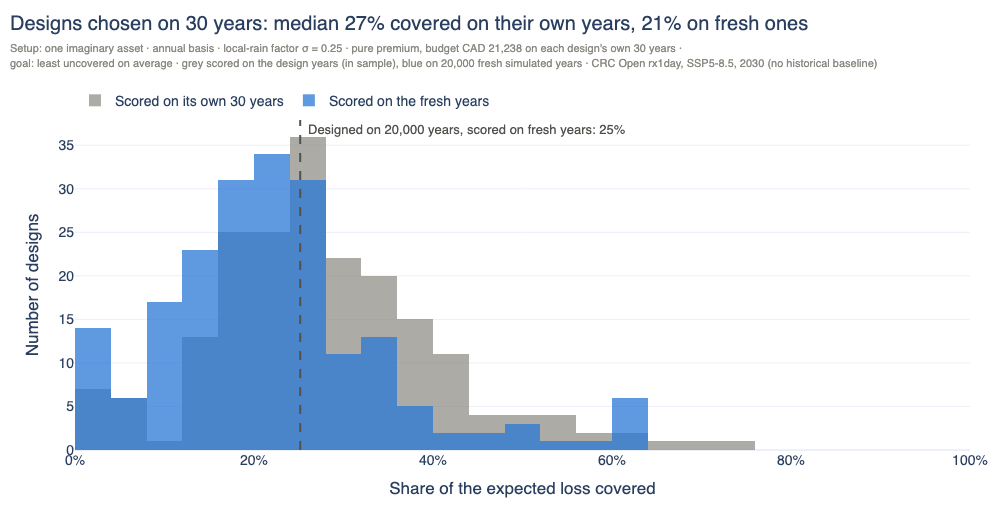

Over 200 designs chosen on 30 simulated years each: 8 in 10 of them cover between 9% and 36% of the expected loss on the 20,000 fresh years, and the 30 years they were built on give no way to tell which is which.


In [14]:
REPEATS = 20 if CI else 200
SHORT = 30
promised, delivered = [], []
for repeat in range(REPEATS):
    short_years = simulate(seed=1_000 + repeat, n_years=SHORT)
    short_design = design(template("Short record"), short_years, ExpectedUncovered(), budget=Budget(amount=BUDGET), limit=LIMIT)
    promised.append(evaluate(short_design, short_years, split="in_sample", options=OPTIONS).to_pylist()[0]["coverage_ratio"])
    delivered.append(evaluate(short_design, fresh_years, split="out_of_sample", options=OPTIONS).to_pylist()[0]["coverage_ratio"])
promised, delivered = np.array(promised, dtype=float), np.array(delivered, dtype=float)
long_design = results.loc["Least uncovered on average", "coverage_ratio"]

fig = go.Figure()
fig.add_trace(go.Histogram(x=promised, xbins=dict(start=0, end=1.0001, size=0.04), name=f"Scored on its own {SHORT} years", marker_color=MUTED, opacity=0.7,
                           hovertemplate="Coverage %{x}: %{y} designs<extra></extra>"))
fig.add_trace(go.Histogram(x=delivered, xbins=dict(start=0, end=1.0001, size=0.04), name="Scored on the fresh years", marker_color=BLUE, opacity=0.75,
                           hovertemplate="Coverage %{x}: %{y} designs<extra></extra>"))
fig.add_vline(x=long_design, line=dict(color=INK, width=2, dash="dash"))
fig.add_annotation(x=long_design, y=1, yref="paper", text=f"Designed on {N_YEARS:,} years, scored on fresh years: {long_design:.0%}", showarrow=False,
                   xanchor="left", xshift=6, font=dict(color=INK, size=13))
layout(fig, f"Designs chosen on {SHORT} years: median {np.median(promised):.0%} covered on their own years, {np.median(delivered):.0%} on fresh ones",
       f"Setup: one imaginary asset · annual basis · local-rain factor σ = {SIGMA} · pure premium, budget {cad(BUDGET)} on each design's own {SHORT} years ·<br>"
       f"goal: least uncovered on average · grey scored on the design years (in sample), blue on {N_YEARS:,} fresh simulated years · CRC Open rx1day, SSP5-8.5, {HORIZON} (no historical baseline)",
       barmode="overlay", xaxis=dict(title="Share of the expected loss covered", tickformat=".0%", range=[0, 1]), yaxis_title="Number of designs",
       legend=dict(orientation="h", yanchor="bottom", y=1.01, x=0), height=520)
fig.show()
low, high = np.percentile(delivered, [10, 90])
print(f"Over {REPEATS} designs chosen on {SHORT} simulated years each: 8 in 10 of them cover between {low:.0%} and {high:.0%} of the expected loss "
      f"on the {N_YEARS:,} fresh years, and the {SHORT} years they were built on give no way to tell which is which.")

> 💡 **Key idea: test on years you did not design on.** A cover fitted to a short
> record looks better on that record than it is, and the spread between records is
> wide. Hazard curves make the honest test cheap: you can draw as many fresh years
> as you like.
> In the module that is `split=FreshDraws(...)` for a plan, or `compare(..., split="out_of_sample")`
> for your own years, and every row of the result says which one it is.

## 7. What would it have paid in real years?

Simulated years test a cover against what **could** happen. Real years show what
**did**. CRC Open describes a future and has no past, so for real years we read
**ERA5**, the weather record of the [rain question](how_hard_will_it_rain.ipynb):
the wettest day of each year from 1959 to 2021 for the grid cell around Toronto.

This free copy has grid cells about 165 km across, far larger than the hexagon, so
it smooths out the storms a single street feels. That makes it a different,
blurrier index. Nothing is designed here: we only ask what the same first cover
would have paid on that record.

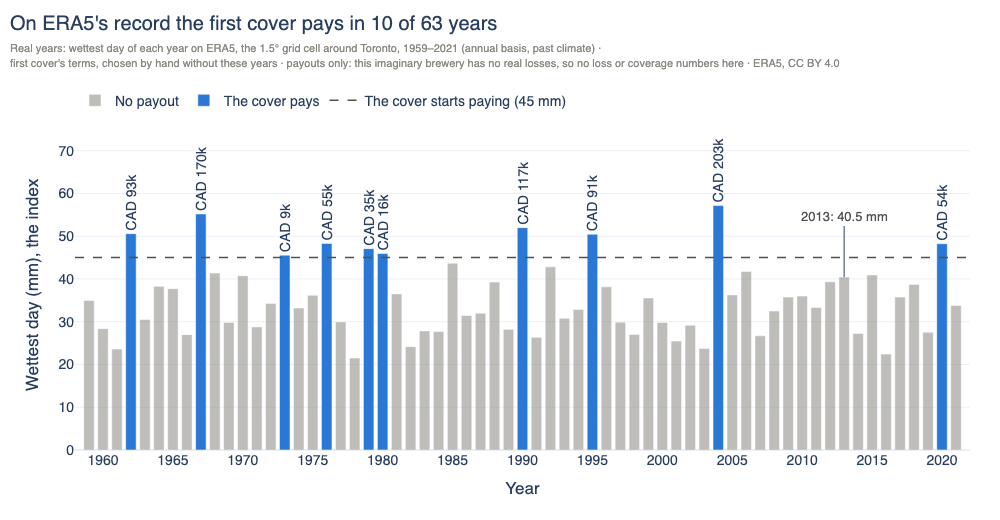

1959–2021: pays in 10 of 63 years, CAD 842,428 in total; never the full CAD 500,000, because the cell's rain never reaches 75 mm (wettest day on record here: 57.2 mm, in 2004).


In [15]:
ERA5_YEARS = (2014, 2021) if CI else (1959, 2021)   # the first run takes about 20 seconds a year; later runs read the cache

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    era5_annual = (
        HazardDataset.era5("rx1day", store="wb2-1p5")
        .for_area((ASSET["longitude"] - 0.1, ASSET["latitude"] - 0.1, ASSET["longitude"] + 0.1, ASSET["latitude"] + 0.1))
        .years(*ERA5_YEARS)
        .cache(DATA / "era5", mode="reuse")
        .canonicalize(policy=BlockExtremaPolicy.curated(h3_resolution=5, minimum_years=8 if CI else 20))
        .annual_extremes()
    )
series = AnnualSeries.nearest_cell(era5_annual, longitude=ASSET["longitude"], latitude=ASSET["latitude"], unit="mm/day", spacing=(1.5, 1.5))
era5_years, era5_rain = np.asarray(series.years, dtype=int), np.asarray(series.values, dtype=float)
era5_paid = first_cover.payout_values(era5_rain)
paying = era5_paid > 0

fig = go.Figure()
fig.add_trace(go.Bar(x=era5_years[~paying], y=era5_rain[~paying], name="No payout", marker_color=MUTED, opacity=0.55,
                     hovertemplate="%{x}: wettest day %{y:.1f} mm, no payout<extra></extra>"))
fig.add_trace(go.Bar(x=era5_years[paying], y=era5_rain[paying], name="The cover pays", marker_color=BLUE,
                     text=[f"CAD {value / 1000:.0f}k" for value in era5_paid[paying]], textposition="outside", textangle=-90, constraintext="none", cliponaxis=False,
                     hovertemplate="%{x}: wettest day %{y:.1f} mm, pays CAD %{customdata:,.0f}<extra></extra>", customdata=era5_paid[paying]))
fig.add_trace(go.Scatter(x=[era5_years.min() - 1, era5_years.max() + 1], y=[45, 45], mode="lines", name="The cover starts paying (45 mm)",
                         line=dict(color=INK, width=1.5, dash="dash"), hoverinfo="skip"))
if 2013 in era5_years:
    rain_2013 = float(era5_rain[era5_years == 2013][0])
    fig.add_annotation(x=2013, y=rain_2013, text=f"2013: {rain_2013:.1f} mm", showarrow=True, arrowhead=0, ax=0, ay=-60, font=dict(color=INK, size=13))
layout(fig, f"On ERA5's record the first cover pays in {int(paying.sum())} of {len(era5_years)} years",
       f"Real years: wettest day of each year on ERA5, the 1.5° grid cell around Toronto, {era5_years.min()}–{era5_years.max()} (annual basis, past climate) ·<br>"
       f"first cover's terms, chosen by hand without these years · payouts only: this imaginary brewery has no real losses, so no loss or coverage numbers here · ERA5, CC BY 4.0",
       xaxis=dict(title="Year", dtick=5), yaxis=dict(title="Wettest day (mm), the index", range=[0, era5_rain.max() * 1.35]),
       barmode="overlay", bargap=0.25, legend=dict(orientation="h", yanchor="bottom", y=1.01, x=0), height=520)
fig.show()
print(f"{era5_years.min()}–{era5_years.max()}: pays in {int(paying.sum())} of {len(era5_years)} years, "
      f"{cad(era5_paid.sum())} in total; never the full {cad(500_000)}, because the cell's rain never reaches 75 mm "
      f"(wettest day on record here: {era5_rain.max():.1f} mm, in {int(era5_years[era5_rain.argmax()])}).")

Look at 2013. On 8 July 2013 Toronto had a record storm: the City's
[staff report](https://www.toronto.ca/legdocs/mmis/2013/ex/bgrd/backgroundfile-61502.pdf)
says close to 140 mm of rain fell in the western part of the city in just a few
hours, and that Toronto Water received over 4,700 complaints about basement
flooding. Yet the wettest day of 2013 on ERA5's cell stayed below the 45 mm
attachment, so **a cover written on this index would have paid nothing in the year
of the flood**.

> 💡 **Key idea: the choice of index is part of the design.** A coarse grid cell is
> cheap, global and impossible to argue with, but it blurs local storms. A station
> or a fine grid sees more and costs more to run. The right index is the one whose
> years line up with your losses, and you can only tell by testing it.

## 8. Build your own

Your turn. Pick the rain level where the cover starts paying with the slider, and
the most it can pay with the buttons. Each combination was computed in advance with
the module on the same fresh years, so this works without running anything. The
payout function is on the left; on the right is how it does.

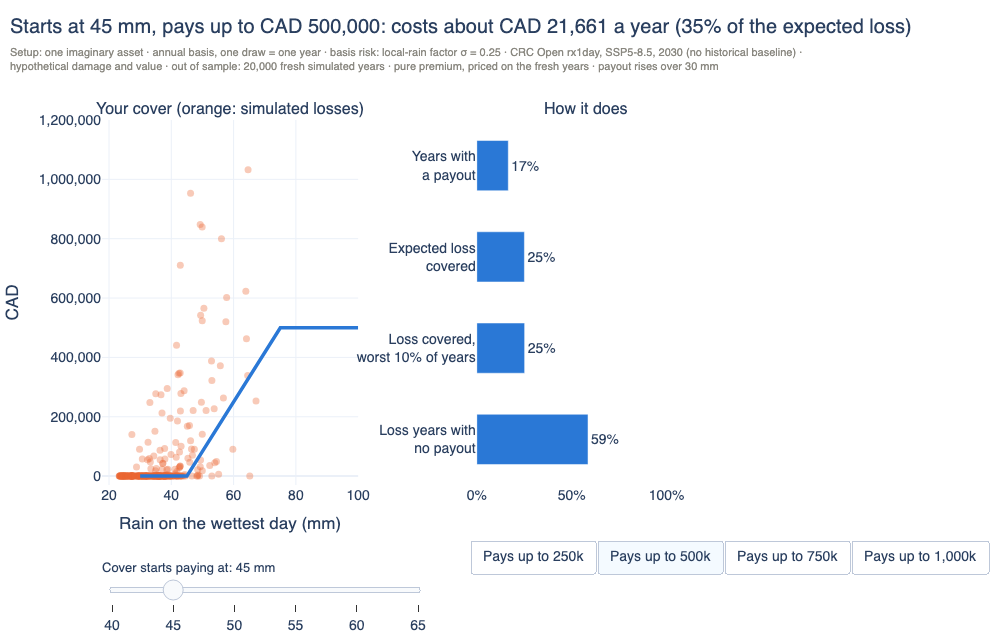

In [16]:
ATTACHMENTS = (40.0, 45.0, 50.0, 55.0, 60.0, 65.0)
MAXIMA = (250_000.0, 500_000.0, 750_000.0, 1_000_000.0)
EXHAUSTION_GAP = 30.0    # the payout reaches its maximum 30 mm after it starts

covers = {(attachment, maximum): Cover(index, LinearPayout(attachment, attachment + EXHAUSTION_GAP, maximum), payout_unit="CAD",
                                       label=f"{attachment:.0f} mm, up to {maximum:,.0f}")
          for maximum in MAXIMA for attachment in ATTACHMENTS}
grid_table = compare(list(covers.values()), fresh_years, split="out_of_sample", design_sample=design_years,
                     options=MetricOptions(betas=(0.9,), return_periods=(10,), loss_thresholds=(0.0,))).to_pandas().set_index("cover_label")

METRICS = {"Years with<br>a payout": None, "Expected loss<br>covered": "coverage_ratio",
           "Loss covered,<br>worst 10% of years": "tail_coverage_b0_9", "Loss years with<br>no payout": "false_negative_rate_l0"}
fig = make_subplots(rows=1, cols=2, column_widths=[0.54, 0.46], horizontal_spacing=0.2,
                    subplot_titles=("Your cover (orange: simulated losses)", "How it does"))
fig.add_trace(go.Scatter(x=rain_years[:300], y=loss_years[:300], mode="markers", name="Simulated years: the loss",
                         marker=dict(size=7, color=ORANGE, opacity=0.35), hoverinfo="skip"), row=1, col=1)
trace_of = {}
plot_rain = np.linspace(30.0, 100.0, 141)
for key, item in covers.items():
    row = grid_table.loc[item.label]
    values = [row[column] if column else float((item.payout_values(rain_years) > 0).mean()) for column in METRICS.values()]
    first = len(fig.data)
    fig.add_trace(go.Scatter(x=plot_rain, y=item.payout_values(plot_rain), mode="lines", name="Your cover", showlegend=False,
                             line=dict(color=BLUE, width=3.5), visible=False,
                             hovertemplate="%{x:.0f} mm: pays CAD %{y:,.0f}<extra></extra>"), row=1, col=1)
    fig.add_trace(go.Bar(x=values, y=list(METRICS), orientation="h", marker_color=BLUE, visible=False, showlegend=False, width=0.55,
                         text=[f"{value:.0%}" for value in values], textposition="outside", cliponaxis=False,
                         hovertemplate="%{y}: %{x:.1%}<extra></extra>"), row=1, col=2)
    trace_of[key] = first


def visible_cover(attachment, maximum):
    selected = trace_of[attachment, maximum]
    return [True] + [selected <= number <= selected + 1 for number in range(1, len(fig.data))]


def cover_title(attachment, maximum):
    row = grid_table.loc[covers[attachment, maximum].label]
    return (f"Starts at {attachment:.0f} mm, pays up to {cad(maximum)}: "
            f"costs about {cad(row['premium'])} a year ({row['premium'] / row['expected_loss']:.0%} of the expected loss)")


def attachment_slider(maximum, active=1):
    return dict(active=active, currentvalue=dict(prefix="Cover starts paying at: ", suffix=" mm", font=dict(size=13)), pad=dict(t=70), len=0.55,
                steps=[dict(method="update", label=f"{attachment:.0f}",
                            args=[{"visible": visible_cover(attachment, maximum)}, {"title.text": cover_title(attachment, maximum)}])
                       for attachment in ATTACHMENTS])


START_ATTACHMENT, START_MAXIMUM = ATTACHMENTS[1], MAXIMA[1]
for number in (trace_of[START_ATTACHMENT, START_MAXIMUM], trace_of[START_ATTACHMENT, START_MAXIMUM] + 1):
    fig.data[number].visible = True

buttons = [dict(method="update", label=f"Pays up to {maximum / 1000:,.0f}k",
                args=[{"visible": visible_cover(START_ATTACHMENT, maximum)},
                      {"sliders": [attachment_slider(maximum)], "title.text": cover_title(START_ATTACHMENT, maximum)}])
           for maximum in MAXIMA]
layout(fig, cover_title(START_ATTACHMENT, START_MAXIMUM),
       FRESH_SETUP + f" · pure premium, priced on the fresh years · payout rises over {EXHAUSTION_GAP:.0f} mm",
       height=640, bottom=140, showlegend=False, sliders=[attachment_slider(START_MAXIMUM)],
       updatemenus=[dict(type="buttons", direction="right", x=0.62, y=-0.15, xanchor="left", yanchor="top", showactive=True, active=1, buttons=buttons)])
fig.update_xaxes(title_text="Rain on the wettest day (mm)", row=1, col=1)
fig.update_yaxes(title_text="CAD", tickformat=",.0f", range=[-30_000, 1_200_000], row=1, col=1)
fig.update_xaxes(tickformat=".0%", range=[0, 1.15], row=1, col=2)
fig.update_yaxes(autorange="reversed", row=1, col=2)
fig.show()

> 💡 **Key idea: every term moves something you care about.** A cover that starts
> paying earlier pays more often and misses fewer loss years, but it costs more. A
> higher maximum buys protection in the rare years. Your own choice depends on what
> the brewery can absorb, and that is a question the charts can inform but can't
> answer.

## Where next

Everything above can be run as one lazy, documented plan, which also writes a single
comparison table with its setup, seeds, sources and licences. `ParametricPlan` draws
the same simulated years as the function calls above, so the result is the same
numbers:

In [17]:
plan = (
    ParametricPlan.for_evaluation(request, value_column="value_cad", value_unit="CAD")
    .monte_carlo(N_YEARS, seed=42)
    .basis_risk(basis_risk)
    .covers(first_cover, template("Shape"))
    .objective(*[objective for objective, _ in GOALS.values()], budget=Budget(amount=BUDGET), limit=LIMIT)
    .split(FreshDraws(N_YEARS, seed=7))
    .metrics(OPTIONS)
)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ReturnPeriodExtrapolationWarning)  # counted, and stated by setup_text below
    result = plan.write_parquet(DATA / "comparison.parquet")

plan_fresh = result.fresh_samples[ASSET["asset_id"]]
assert plan_fresh.content_hash == fresh_years.content_hash, "the plan and the function calls drew different years"
print(f"The plan drew the same fresh years as the function calls above ({plan_fresh.content_hash[:19]}…).")
print(f"Wrote {result.row_count} rows to {result.output}: every cover, in and out of sample.")
print()
print(setup_text(result.table.filter(pc.equal(result.table["split"], "out_of_sample"))))

The plan drew the same fresh years as the function calls above (sha256:1b1f7e9a7f98…).
Wrote 8 rows to data/parametric_primer/comparison.parquet: every cover, in and out of sample.

Level: asset (Wet Basement Brewing). Scenario: baseline. Basis: annual, one draw is one year.
Split: out of sample, fold 0, on fresh Monte Carlo draws: evaluated on 20000 simulated years (draws 0 to 19999); designed on 20000 simulated years (draws 0 to 19999); the leakage check passed: the two share no period of one source.
Seeds: the plan's seed 42; the fresh draws' seed 7.
Sample: Monte Carlo draws from a hazard curve with annual_value_distribution semantics, as the dataset declares. Basis risk: local_rain_factor (damage "sha256:c7eef8f12dda14fb2434b66b9db05108547944018bfc30fa67cdcff98600ecb7", sigma 0.25). Loss: impact expression basement_damage (c7eef8f12dda) for hazard values in mm/day times the asset value in column value_cad, in CAD.
Source: the hazard curve rx1day from provider crc_open, dataset crc

**To go further:**

- Change the rain, the damage curve or the budget above and rerun: the same cells
  work for any place, horizon and payout shape.
- Try a step payout (`StepPayout`), an all-or-nothing payout (`BinaryPayout`) or
  your own function that implements the payout protocol.
- Read the module's [full guide](https://github.com/RiskThinking/crc-sdk/blob/main/docs/parametric.md),
  and the [rain question](how_hard_will_it_rain.ipynb) for what the data can tell you
  on its own.

*An ordinary loss-based policy and a parametric cover answer different questions:
one pays for what happened to you, the other for what happened to the measurement.
This notebook is an illustration of a method, not insurance advice or a price.*

*The tail-risk design ideas in this module come from Marc Prinzing's thesis,
"Tail-Risk Optimized Payout Design in Parametric Insurance".*

*Data: CRC Open by Riskthinking.AI (CC BY-NC 4.0; SSP5-8.5 only, no historical
baseline). ERA5 from the Copernicus Climate Change Service, read through
WeatherBench 2 (CC BY 4.0). The scheme facts in the introduction are from the
linked publications.*